# Credit Portfolio Segmentation and Risk Pattern Analysis


### Project Workflow
1. **Data Loading** – Import the required libraries and load the Lending Club dataset.
2. **Data Preprocessing** – Handle missing values, duplicates, and data quality issues.
3. **Feature Engineering** – Create relevant financial and borrower-related features.
4. **Exploratory Data Analysis (EDA)** – Examine distributions, relationships, and patterns in the data.
5. **Feature Preparation** – Apply encoding, scaling, and dimensionality reduction using PCA.
6. **Clustering** – Apply K-Means, Hierarchical Clustering, and DBSCAN.
7. **Cluster Visualization** – Visualize the segments using PCA, t-SNE, and UMAP.
8. **Cluster Profiling** – Analyze the characteristics of each borrower segment.
9. **Default Pattern Analysis** – Compare historical default rates across clusters.
10. **Anomaly Detection** – Identify unusual borrower profiles.
11. **Model Export and Conclusion** – Save the trained model and summarize the findings.


## 1. Setup and loading data

In [66]:
import warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
import umap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200, "display.max_columns", 40)

RANDOM_STATE = 42          
DATA_PATH = "data/raw/loans_granting_model_dataset.csv"
SAMPLE_SIZE = 10_000       
K_FINAL = 5                

In [67]:
raw = pd.read_csv("loans_granting_model_dataset.csv")

print("Dataset dimensions:", raw.shape)

raw.head()

Dataset dimensions: (1347681, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


In [68]:
# # Checking Data Types, Missing Values, and Unique Values in Each Column
column_summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(),
})
print(column_summary)

                    dtype  missing   unique
id                  int64        0  1347681
issue_d            object        0      139
revenue           float64        0    65608
dti_n             float64        0     7068
loan_amnt           int64        0     1560
fico_n            float64        0       48
experience_c        int64        0        2
emp_length         object        0       12
purpose            object        0       14
home_ownership_n   object        0        4
addr_state         object        0       51
zip_code           object        1      945
Default             int64        0        2
title              object    16657    61451
desc               object  1228582   109539


## 2. Data cleaning

In [69]:
df = raw.copy()
log = []                       # we record every cleaning step
n0 = len(df)

# 2.1 duplicates
df = df.drop_duplicates()
log.append(("Exact duplicate rows removed", n0 - len(df)))
n = len(df)
df = df.drop_duplicates(subset="id")
log.append(("Repeated loan ids removed", n - len(df)))

# 2.2 drop columns that are identifiers, mostly empty, duplicated or constant
drop_cols = ["id", "desc", "title", "zip_code", "experience_c"]
df = df.drop(columns=drop_cols)
log.append(("Columns dropped", len(drop_cols)))

# 2.3 make text values consistent
df["purpose"] = df["purpose"].str.strip().str.lower()
df["home_ownership_n"] = df["home_ownership_n"].str.strip().str.upper()
df["addr_state"] = df["addr_state"].str.strip().str.upper()
df["emp_length"] = df["emp_length"].str.strip()

# 2.4 home ownership 'OTHER' is tiny (0.04%) and ambiguous
n = len(df)
df = df[df["home_ownership_n"].isin(["MORTGAGE", "RENT", "OWN"])]
log.append(("Rows with home ownership 'OTHER' removed", n - len(df)))

# 2.5 impossible debt-to-income values (999 is a placeholder)
n = len(df)
df = df[(df["dti_n"] >= 0) & (df["dti_n"] <= 100)]
log.append(("Rows with dti > 100 removed", n - len(df)))

# 2.6 any remaining missing values in key columns
key_cols = ["revenue", "dti_n", "loan_amnt", "fico_n", "purpose",
            "home_ownership_n", "addr_state", "Default"]
n = len(df)
df = df.dropna(subset=key_cols)
log.append(("Rows with missing key values removed", n - len(df)))
pd.DataFrame(log, columns=["step", "rows_affected"])

,step,rows_affected
0,Exact duplicate rows removed,0
1,Repeated loan ids removed,0
2,Columns dropped,5
3,Rows with home ownership 'OTHER' removed,517
4,Rows with dti > 100 removed,532
5,Rows with missing key values removed,0


In [70]:
# 2.7 dates -> time features (used for trends, NOT for clustering)
df["issue_date"] = pd.to_datetime(df["issue_d"], format="%b-%Y")
df["issue_year"] = df["issue_date"].dt.year
df["issue_month"] = df["issue_date"].dt.month
df = df.drop(columns=["issue_d"])

# 2.8 employment length: text -> years. 'NI' means "no information" -> missing
EMP_MAP = {"< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4,
           "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9,
           "10+ years": 10}
df["emp_years"] = df["emp_length"].map(EMP_MAP)
df["emp_info_missing"] = df["emp_years"].isna().astype(int)
print("Employment 'NI' rows:", df["emp_info_missing"].sum())

# 2.9 US region from state (for the geographic analysis)
REGIONS = {"Northeast": "CT ME MA NH RI VT NJ NY PA",
           "Midwest": "IL IN MI OH WI IA KS MN MO NE ND SD",
           "South": "DE FL GA MD NC SC VA DC WV AL KY MS TN AR LA OK TX",
           "West": "AZ CO ID MT NV NM UT WY AK CA HI OR WA"}
STATE_REGION = {s: r for r, states in REGIONS.items() for s in states.split()}
df["region"] = df["addr_state"].map(STATE_REGION)

df = df.reset_index(drop=True)
print("Clean data:", df.shape, "| overall default rate: %.2f%%" % (df["Default"].mean() * 100))
del raw   # free memory

Employment 'NI' rows: 77906
Clean data: (1346632, 15) | overall default rate: 19.98%


## 3. Feature engineering

* **log(1 + income)** - income has a highly uneven distribution, so the log transformation reduces its skewness
* **loan_to_income** = loan amount divided by income (a basic measure of loan affordability)
* **Outliers** - extreme values in income, DTI and loan-to-income are limited to their 99.5th percentile (winsorising)
* **emp_years** - 'NI' replaced with the median value
* **purpose_group** - 13 loan purposes combined into 4 categories to keep one-hot encoding manageable

In [71]:
CAP_Q = 0.995
caps = {
    "revenue": float(df["revenue"].quantile(CAP_Q)),
    "dti_n": float(df["dti_n"].quantile(CAP_Q)),
    "loan_to_income": float((df["loan_amnt"] / df["revenue"]).quantile(CAP_Q)),
    "emp_years_median": float(df["emp_years"].median()),
}
print(caps)

def engineer_features(data, caps):
    """Create the model-ready columns (works for one borrower or the whole table)."""
    out = data.copy()
    out["log_income"] = np.log1p(out["revenue"].clip(upper=caps["revenue"]))
    out["dti_n"] = out["dti_n"].clip(upper=caps["dti_n"])
    out["loan_to_income"] = (out["loan_amnt"] / out["revenue"]).clip(upper=caps["loan_to_income"])
    out["emp_years"] = out["emp_years"].fillna(caps["emp_years_median"])
    out["purpose_group"] = np.where(
        out["purpose"].isin(["debt_consolidation", "credit_card", "home_improvement"]),
        out["purpose"], "other")
    return out

df = engineer_features(df, caps)
df[["revenue", "log_income", "dti_n", "loan_amnt", "fico_n", "emp_years",
    "loan_to_income", "purpose_group", "home_ownership_n"]].head()

{'revenue': 325000.0, 'dti_n': 39.88, 'loan_to_income': 0.5, 'emp_years_median': 6.0}


,revenue,log_income,dti_n,loan_amnt,fico_n,emp_years,loan_to_income,purpose_group,home_ownership_n
0,55000.0,10.915107,5.91,3600,677.0,10.0,0.065455,debt_consolidation,MORTGAGE
1,65000.0,11.082158,16.06,24700,717.0,10.0,0.380000,other,MORTGAGE
2,71000.0,11.170449,13.85,20000,697.0,10.0,0.281690,home_improvement,MORTGAGE
3,104433.0,11.556311,25.37,10400,697.0,3.0,0.099585,other,MORTGAGE
4,34000.0,10.434145,10.20,11950,692.0,4.0,0.351471,debt_consolidation,RENT


## 4. Exploratory Data Analysis (EDA)

In [72]:
num_cols = ["revenue", "dti_n", "loan_amnt", "fico_n", "emp_years", "loan_to_income"]
df[num_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
revenue,1346632.0,77353.693,70360.803,1896.0,46560.000,65000.000,92000.000,10999200.00
dti_n,1346632.0,18.147,8.458,0.0,11.810,17.630,24.060,39.88
loan_amnt,1346632.0,14406.599,8713.860,500.0,7975.000,12000.000,20000.000,40000.00
fico_n,1346632.0,698.155,31.848,612.0,672.000,692.000,712.000,847.50
emp_years,1346632.0,5.965,3.583,0.0,3.000,6.000,10.000,10.00
loan_to_income,1346632.0,0.210,0.112,0.0,0.123,0.197,0.286,0.50


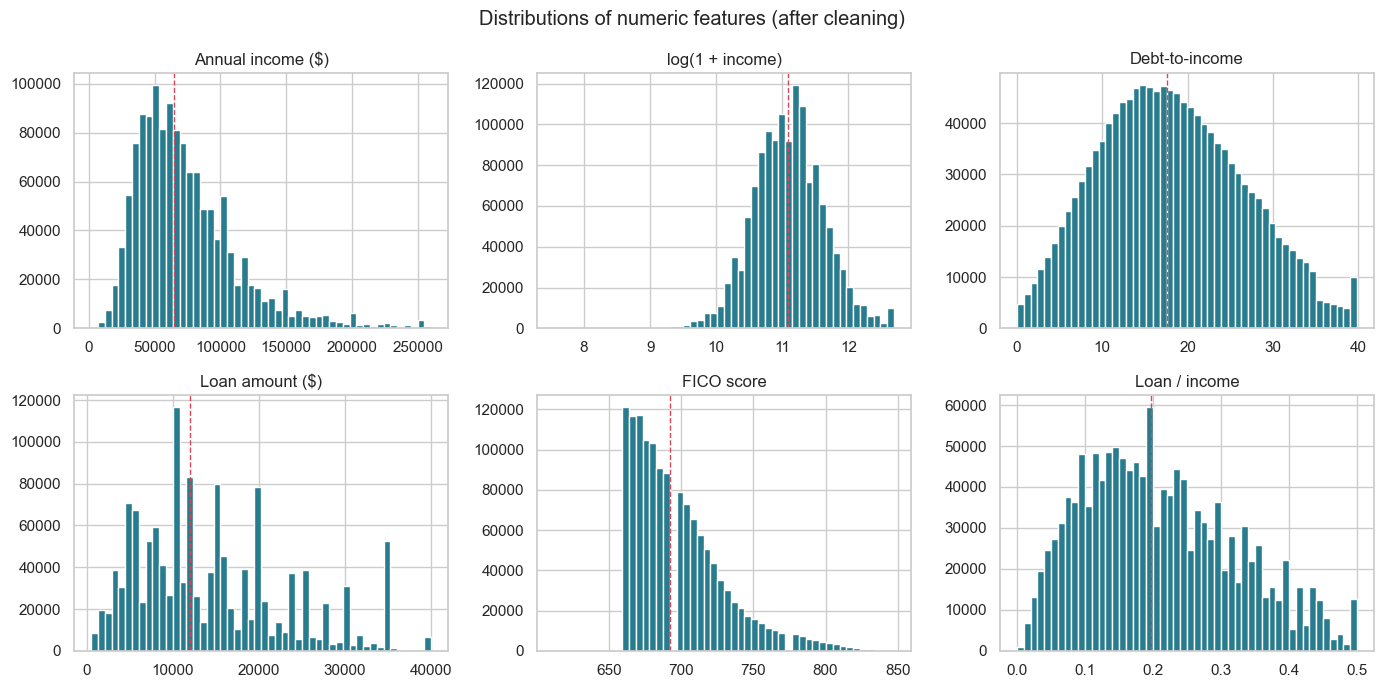

In [73]:
# 4.1 distributions of the numeric features
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
items = [("revenue", "Annual income ($)"), ("log_income", "log(1 + income)"),
         ("dti_n", "Debt-to-income"), ("loan_amnt", "Loan amount ($)"),
         ("fico_n", "FICO score"), ("loan_to_income", "Loan / income")]
for ax, (col, label) in zip(axes.ravel(), items):
    data = df[col]
    if col == "revenue":                       # show up to the 99th percentile only
        data = data[data <= data.quantile(0.99)]
    ax.hist(data, bins=50, color="#287C8E", edgecolor="white")
    ax.axvline(data.median(), color="#D1495B", ls="--", lw=1)
    ax.set_title(label)
plt.suptitle("Distributions of numeric features (after cleaning)")
plt.tight_layout(); plt.show()

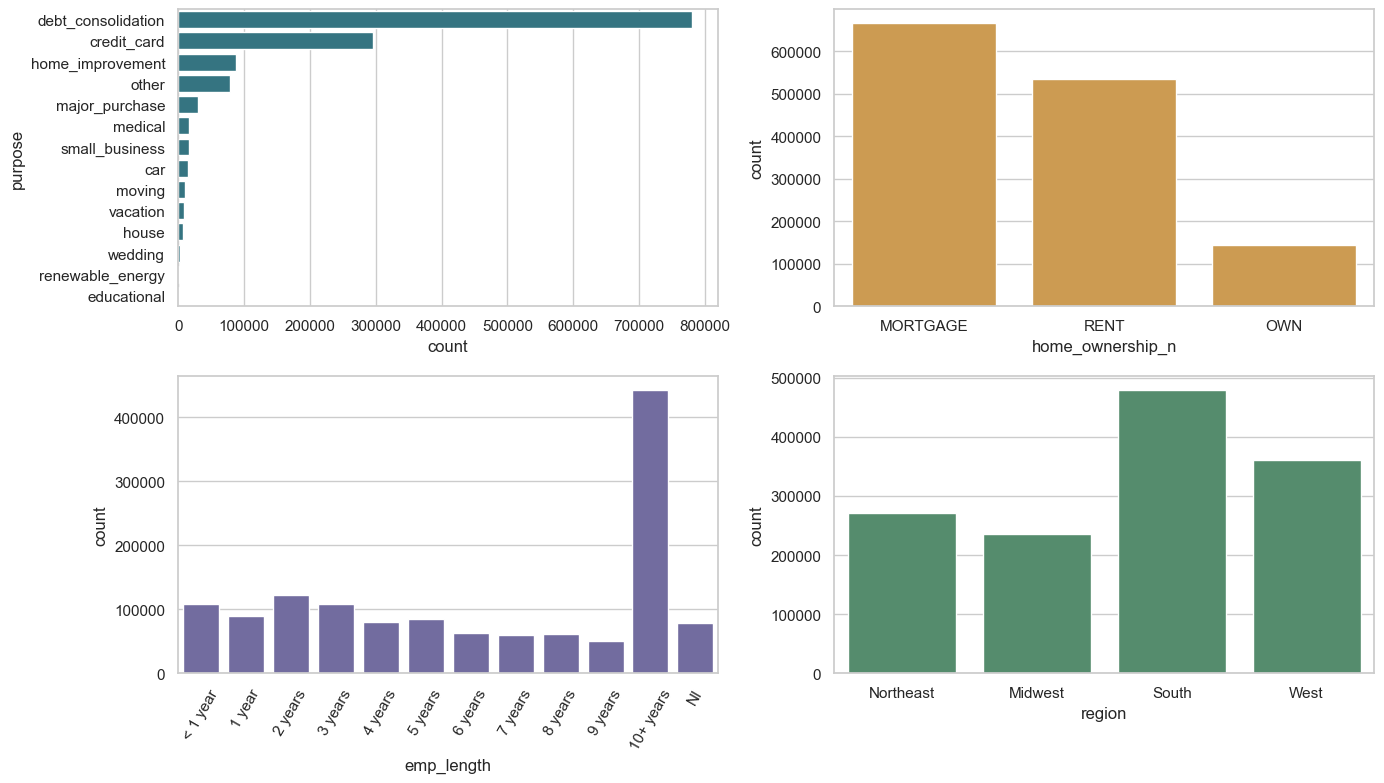

In [74]:
# 4.2 categorical features
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
sns.countplot(y="purpose", data=df, order=df["purpose"].value_counts().index, ax=axes[0, 0], color="#287C8E")
sns.countplot(x="home_ownership_n", data=df, ax=axes[0, 1], color="#E09F3E")
emp_order = ["< 1 year"] + ["1 year"] + [f"{i} years" for i in range(2, 10)] + ["10+ years", "NI"]
sns.countplot(x="emp_length", data=df, order=emp_order, ax=axes[1, 0], color="#6C63A8")
axes[1, 0].tick_params(axis="x", rotation=60)
sns.countplot(x="region", data=df, ax=axes[1, 1], color="#4C956C")
plt.tight_layout(); plt.show()

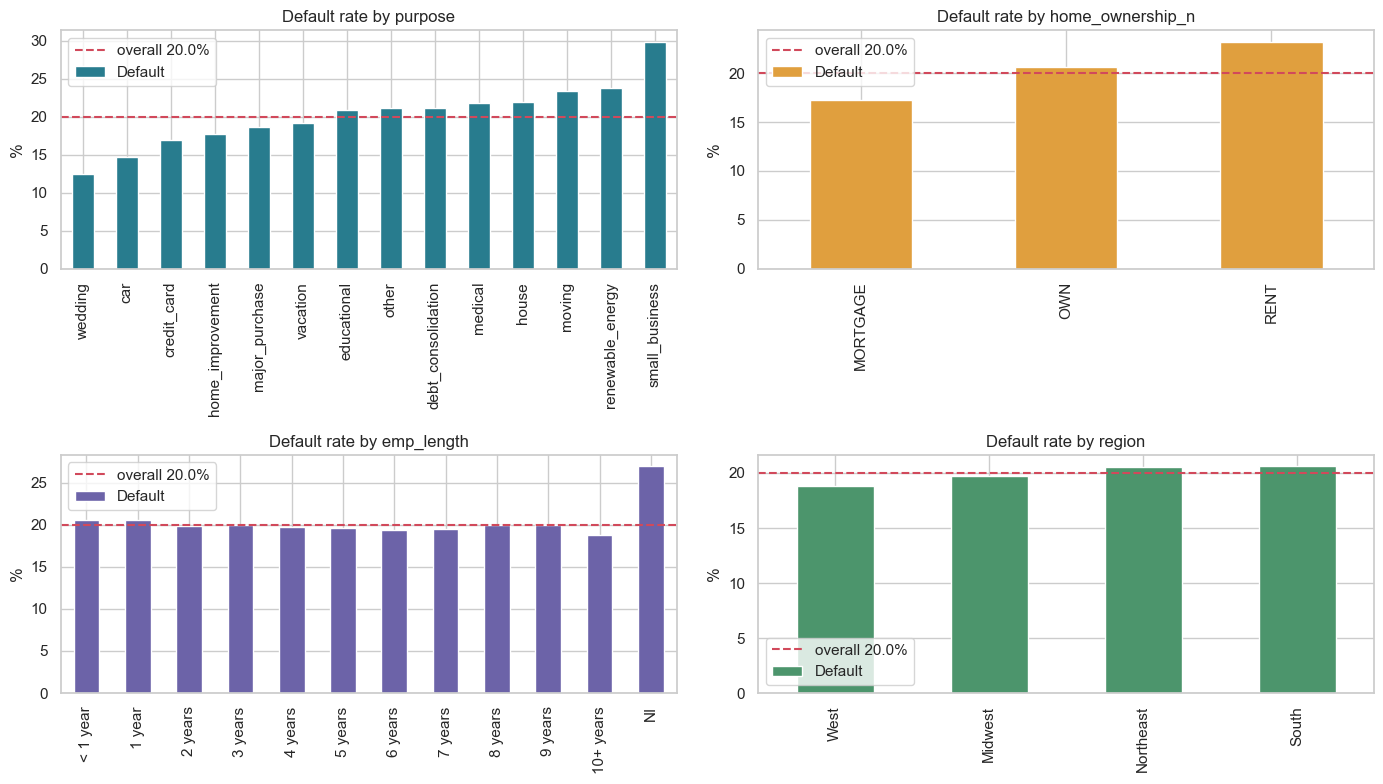

In [75]:
# 4.3 default rate by category (EDA only - Default is NOT a clustering feature)
overall = df["Default"].mean() * 100
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col, order, color in [(axes[0, 0], "purpose", None, "#287C8E"), (axes[0, 1], "home_ownership_n", None, "#E09F3E"),
                       (axes[1, 0], "emp_length", emp_order, "#6C63A8"), (axes[1, 1], "region", None, "#4C956C")]:
    rate = df.groupby(col)["Default"].mean() * 100
    rate = rate.reindex(order) if order else rate.sort_values()
    rate.plot.bar(ax=ax, color=color)
    ax.axhline(overall, color="#D1495B", ls="--", label=f"overall {overall:.1f}%")
    ax.set_title(f"Default rate by {col}"); ax.set_ylabel("%"); ax.set_xlabel(""); ax.legend()
plt.tight_layout(); plt.show()

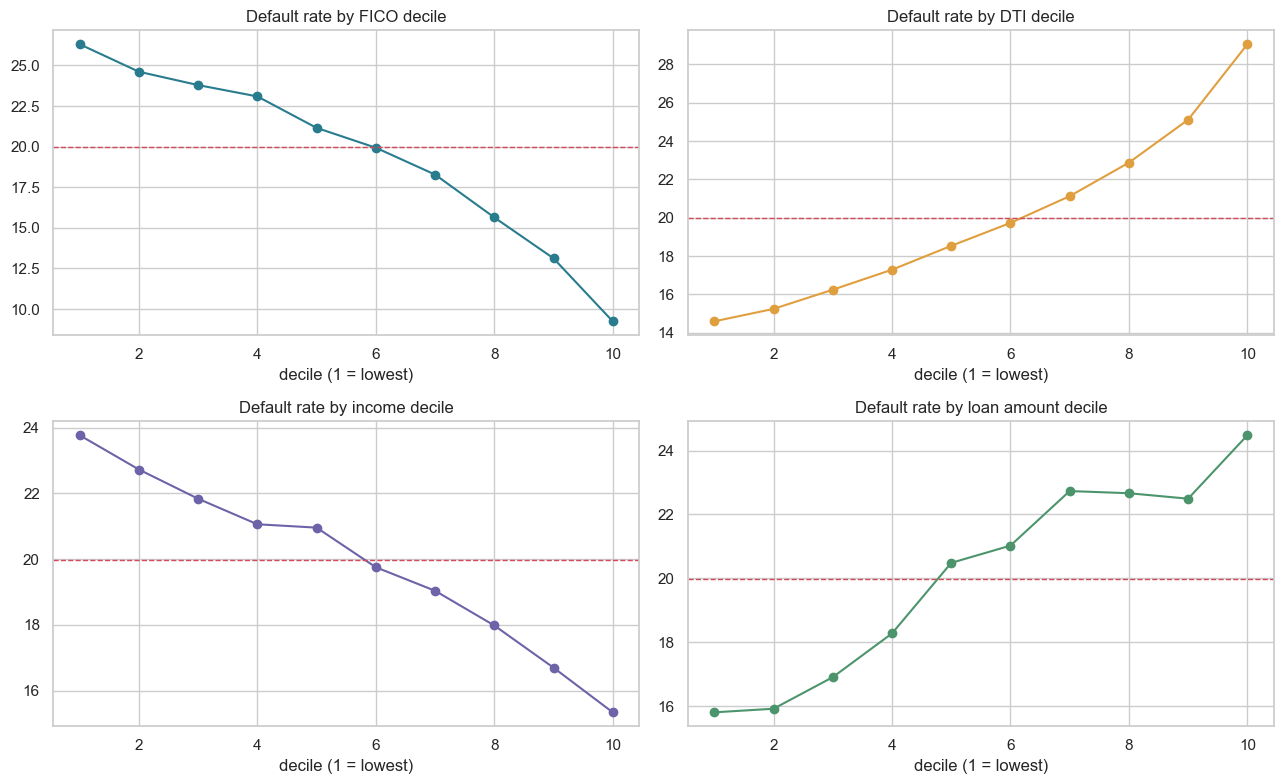

In [76]:
# 4.4 default rate by decile of each numeric variable
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (col, label), color in zip(axes.ravel(), [("fico_n", "FICO"), ("dti_n", "DTI"),
                                           ("revenue", "income"), ("loan_amnt", "loan amount")],
                                  ["#287C8E", "#E09F3E", "#6C63A8", "#4C956C"]):
    rate = df.groupby(pd.qcut(df[col], 10, duplicates="drop"), observed=True)["Default"].mean() * 100
    ax.plot(range(1, len(rate) + 1), rate.values, marker="o", color=color)
    ax.axhline(overall, color="#D1495B", ls="--", lw=1)
    ax.set_title(f"Default rate by {label} decile"); ax.set_xlabel("decile (1 = lowest)")
plt.tight_layout(); plt.show()

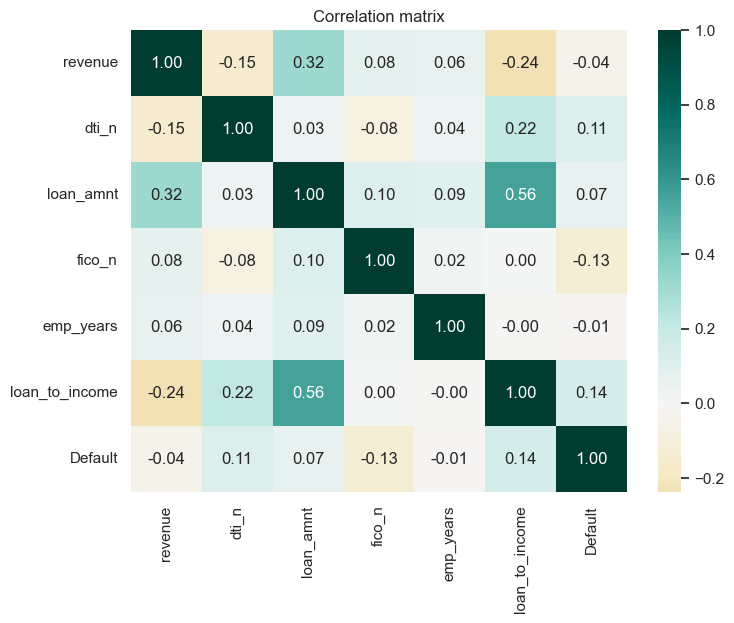

In [77]:
# 4.5 correlation (Default included for EDA only)
corr = df[num_cols + ["Default"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="BrBG", center=0)
plt.title("Correlation matrix"); plt.show()

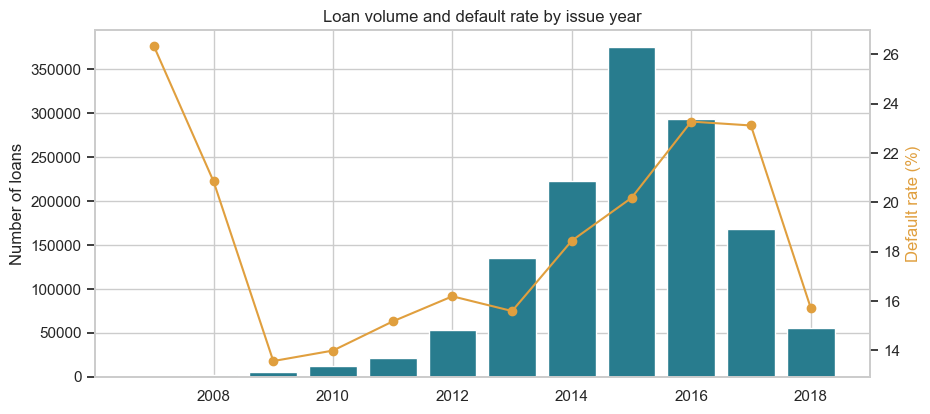

issue_year,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
loans,596.00,2345.00,5196.00,12534.00,21720.00,53279.00,134804.0,223101.00,375533.00,292916.00,168632.00,55976.00
default_rate,26.34,20.85,13.57,13.99,15.17,16.19,15.6,18.45,20.19,23.28,23.12,15.74


In [78]:
# 4.6 trend by issue year
yearly = df.groupby("issue_year").agg(loans=("Default", "size"), default_rate=("Default", "mean"))
yearly["default_rate"] *= 100
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(yearly.index, yearly["loans"], color="#287C8E"); ax1.set_ylabel("Number of loans")
ax2 = ax1.twinx(); ax2.plot(yearly.index, yearly["default_rate"], color="#E09F3E", marker="o")
ax2.set_ylabel("Default rate (%)", color="#E09F3E"); ax2.grid(False)
plt.title("Loan volume and default rate by issue year"); plt.show()
yearly.round(2).T

## 5. Scaling, encoding and PCA

* Numeric features -> `StandardScaler` (average 0, standard deviation 1) to prevent income values from having more influence than FICO scores.
* Categorical features -> converted using one-hot encoding.
* `Default`, IDs, state and dates are **not** included as clustering inputs.
* PCA retains the components that capture at least 90% of the total variance.

In [79]:
NUMERIC_FEATURES = ["log_income", "dti_n", "loan_amnt", "fico_n", "emp_years", "loan_to_income"]
CATEGORICAL_FEATURES = ["purpose_group", "home_ownership_n"]
feature_cols = NUMERIC_FEATURES + CATEGORICAL_FEATURES
assert "Default" not in feature_cols          # Default must never be a clustering feature

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
])
X = preprocessor.fit_transform(df[feature_cols])
print("Model matrix:", X.shape)
print(list(preprocessor.get_feature_names_out()))

Model matrix: (1346632, 13)
['num__log_income', 'num__dti_n', 'num__loan_amnt', 'num__fico_n', 'num__emp_years', 'num__loan_to_income', 'cat__purpose_group_credit_card', 'cat__purpose_group_debt_consolidation', 'cat__purpose_group_home_improvement', 'cat__purpose_group_other', 'cat__home_ownership_n_MORTGAGE', 'cat__home_ownership_n_OWN', 'cat__home_ownership_n_RENT']


Components needed for 90% variance: 7 (explains 94.0%)


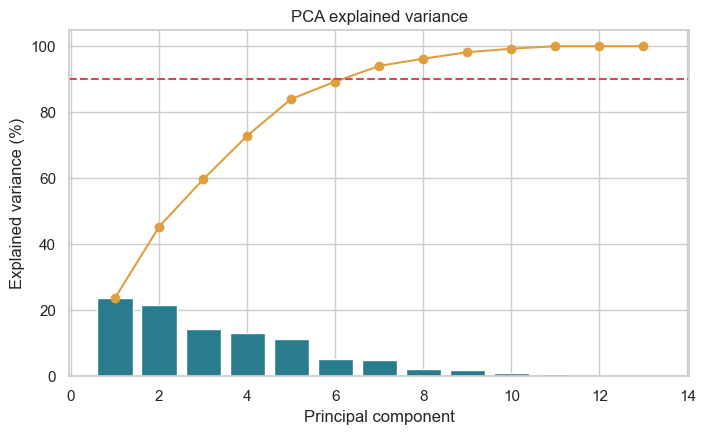

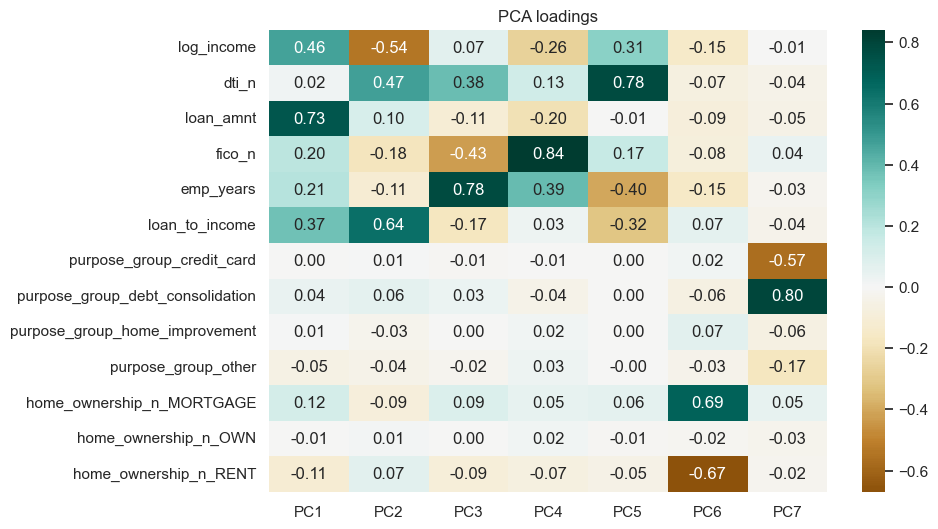

In [80]:
# PCA: fit all components first to look at the explained variance
pca_full = PCA(random_state=RANDOM_STATE).fit(X)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_keep = int(np.searchsorted(cum, 0.90) + 1)
print(f"Components needed for 90% variance: {n_keep} (explains {cum[n_keep-1]:.1%})")

plt.figure(figsize=(8, 4.5))
plt.bar(range(1, len(cum) + 1), pca_full.explained_variance_ratio_ * 100, color="#287C8E")
plt.plot(range(1, len(cum) + 1), cum * 100, marker="o", color="#E09F3E")
plt.axhline(90, color="#D1495B", ls="--"); plt.xlabel("Principal component"); plt.ylabel("Explained variance (%)")
plt.title("PCA explained variance"); plt.show()

pca = PCA(n_components=n_keep, random_state=RANDOM_STATE).fit(X)
Z = pca.transform(X)                      # data used for clustering
names = [n.split("__")[1] for n in preprocessor.get_feature_names_out()]
loadings = pd.DataFrame(pca.components_.T, index=names, columns=[f"PC{i+1}" for i in range(n_keep)])
plt.figure(figsize=(9, 6)); sns.heatmap(loadings, annot=True, fmt=".2f", cmap="BrBG", center=0)
plt.title("PCA loadings"); plt.show()

## 6. Clustering

Hierarchical clustering and DBSCAN take longer to process 1.3 million records, so a **random selection of 10,000 borrowers** is used to compare the algorithms. The final K-Means model is trained using **the complete dataset**.

In [81]:
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(df), SAMPLE_SIZE, replace=False)
Zs = Z[sample_idx]
sample = df.iloc[sample_idx].reset_index(drop=True)
print(Zs.shape)

(10000, 7)


### 6.1 Choosing the number of clusters (k)

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,55605.077,0.169,2.096,2038.594
1,3,48635.196,0.146,1.898,1881.579
2,4,44442.624,0.149,1.785,1686.918
3,5,40895.297,0.145,1.709,1591.545
4,6,38361.672,0.142,1.710,1489.203
5,7,36294.247,0.139,1.665,1406.431
6,8,34759.565,0.139,1.681,1321.645
7,9,33622.000,0.135,1.731,1237.692
8,10,32572.622,0.135,1.714,1171.266


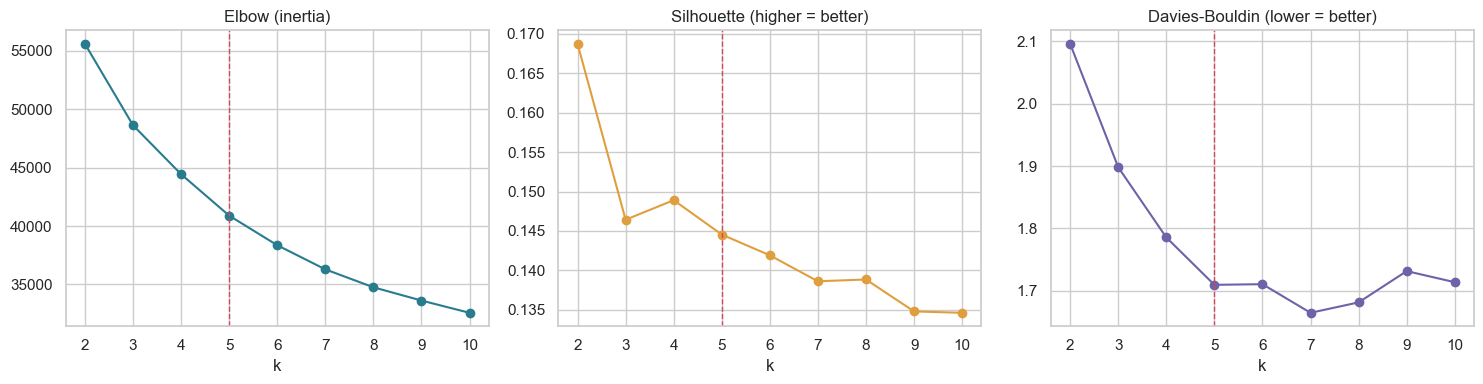

In [82]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Zs)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(Zs, km.labels_),
                 "davies_bouldin": davies_bouldin_score(Zs, km.labels_),
                 "calinski_harabasz": calinski_harabasz_score(Zs, km.labels_)})
k_table = pd.DataFrame(rows)
display(k_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(k_table["k"], k_table["inertia"], marker="o", color="#287C8E"); axes[0].set_title("Elbow (inertia)")
axes[1].plot(k_table["k"], k_table["silhouette"], marker="o", color="#E09F3E"); axes[1].set_title("Silhouette (higher = better)")
axes[2].plot(k_table["k"], k_table["davies_bouldin"], marker="o", color="#6C63A8"); axes[2].set_title("Davies-Bouldin (lower = better)")
for ax in axes: ax.axvline(K_FINAL, color="#D1495B", ls="--", lw=1); ax.set_xlabel("k")
plt.tight_layout(); plt.show()

**Choice of k = 5.** Although the silhouette score is highest at k = 2, it remains nearly unchanged (around 0.14 to 0.15) for k = 3 to 6, making it difficult to select k using this metric alone. The two-cluster solution is too broad, so k = 4, 5 and 6 were examined through profiling. **k = 5 produced more distinct and interpretable borrower segments** with a favourable Davies-Bouldin score. The final selection is based on practical judgement.

### 6.2 K-Means (fitted on all borrowers)

In [83]:
def order_labels_by(labels, values):
    """Renumber clusters 0..k-1 by ascending median of `values` (here: FICO)."""
    medians = pd.Series(values).groupby(labels).median().sort_values()
    old_to_new = np.zeros(len(medians), dtype=int)
    for new_id, old_id in enumerate(medians.index):
        old_to_new[old_id] = new_id
    return old_to_new[labels], old_to_new

kmeans = KMeans(n_clusters=K_FINAL, n_init=5, random_state=RANDOM_STATE).fit(Z)
df["kmeans_cluster"], old_to_new = order_labels_by(kmeans.labels_, df["fico_n"].values)
sample["kmeans_cluster"] = df["kmeans_cluster"].values[sample_idx]
print(df["kmeans_cluster"].value_counts().sort_index())

kmeans_cluster
0    321694
1    314600
2    292625
3    278497
4    139216
Name: count, dtype: int64


### 6.3 Hierarchical clustering (Ward linkage)

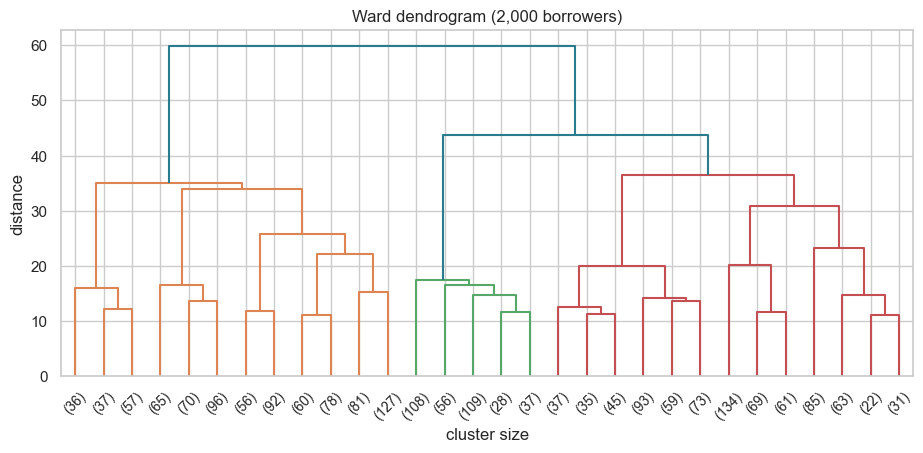

In [84]:
hier_raw = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit_predict(Zs)
sample["hier_cluster"], _ = order_labels_by(hier_raw, sample["fico_n"].values)

link = linkage(Zs[:2000], method="ward")             # dendrogram on a 2,000 subset (readable)
plt.figure(figsize=(11, 4.5))
dendrogram(link, truncate_mode="lastp", p=30, color_threshold=None, above_threshold_color="#287C8E")
plt.title("Ward dendrogram (2,000 borrowers)"); plt.xlabel("cluster size"); plt.ylabel("distance"); plt.show()

### 6.4 DBSCAN

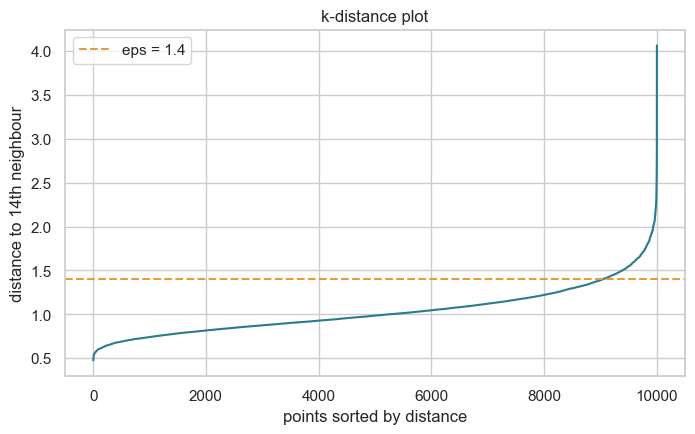

,eps,clusters,noise_pct,silhouette
0,0.6,8,95.95,0.141
1,0.8,7,60.89,-0.112
2,1.0,2,22.80,0.204
3,1.2,1,7.46,NaN
4,1.4,1,2.19,NaN
5,1.6,1,0.55,NaN


dbscan_cluster
 0    9781
-1     219
Name: count, dtype: int64


In [85]:
MIN_SAMPLES = 2 * n_keep          # rule of thumb: 2 x number of dimensions
dist, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Zs).kneighbors(Zs)
kdist = np.sort(dist[:, -1])
EPS = 1.4                         # near the 'knee' of the k-distance curve
plt.figure(figsize=(8, 4.5)); plt.plot(kdist, color="#287C8E"); plt.axhline(EPS, color="#E09F3E", ls="--", label=f"eps = {EPS}")
plt.xlabel("points sorted by distance"); plt.ylabel(f"distance to {MIN_SAMPLES}th neighbour")
plt.title("k-distance plot"); plt.legend(); plt.show()

def eval_labels(Zdata, labels):
    mask = labels != -1
    n_cl = len(set(labels[mask]))
    if n_cl < 2:
        return dict(n_clusters=n_cl, silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    return dict(n_clusters=n_cl, silhouette=silhouette_score(Zdata[mask], labels[mask]),
                davies_bouldin=davies_bouldin_score(Zdata[mask], labels[mask]),
                calinski_harabasz=calinski_harabasz_score(Zdata[mask], labels[mask]))

# how sensitive is DBSCAN to eps?
grid = []
for e in (0.6, 0.8, 1.0, 1.2, 1.4, 1.6):
    lab = DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit_predict(Zs)
    m = eval_labels(Zs, lab)
    grid.append({"eps": e, "clusters": m["n_clusters"], "noise_pct": (lab == -1).mean() * 100,
                 "silhouette": m["silhouette"]})
display(pd.DataFrame(grid).round(3))

sample["dbscan_cluster"] = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Zs)
print(sample["dbscan_cluster"].value_counts())

DBSCAN identifies **one main dense area along with a small percentage of noise points**. When eps is too small, most borrowers are classified as noise; when it is too large, separate groups combine into one. Since borrower records form a continuous distribution rather than distinct clusters, DBSCAN is unsuitable for creating segments in this case. However, its noise points can help identify **unusual borrowers (anomalies)** in section 10.

### 6.5 Algorithm comparison

In [86]:
rows = []
for name, labels in [("K-Means", sample["kmeans_cluster"].values),
                     ("Hierarchical (Ward)", sample["hier_cluster"].values),
                     ("DBSCAN", sample["dbscan_cluster"].values)]:
    m = eval_labels(Zs, labels)
    m.update({"algorithm": name, "noise_pct": (labels == -1).mean() * 100,
              "ARI_vs_kmeans": adjusted_rand_score(sample["kmeans_cluster"], labels)})
    rows.append(m)
comparison = pd.DataFrame(rows)[["algorithm", "n_clusters", "noise_pct", "silhouette",
                                 "davies_bouldin", "calinski_harabasz", "ARI_vs_kmeans"]]
comparison.round(3)

,algorithm,n_clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_kmeans
0,K-Means,5,0.00,0.145,1.701,1586.425,1.000
1,Hierarchical (Ward),5,0.00,0.068,2.311,941.063,0.235
2,DBSCAN,1,2.19,NaN,NaN,NaN,0.008


**K-Means** achieves the highest silhouette score (0.145 compared with 0.068) and a better Davies-Bouldin score. It also produces the most understandable borrower segments, making it the final model. All clustering methods have relatively low silhouette scores because borrowers have gradually changing financial characteristics, resulting in overlapping segments.

## 7. Dimensionality reduction maps (PCA, t-SNE, UMAP)

In [87]:
sample["pca_1"], sample["pca_2"] = Zs[:, 0], Zs[:, 1]

tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
emb = tsne.fit_transform(Zs)
sample["tsne_1"], sample["tsne_2"] = emb[:, 0], emb[:, 1]

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=RANDOM_STATE)
emb = reducer.fit_transform(Zs)
sample["umap_1"], sample["umap_2"] = emb[:, 0], emb[:, 1]
print("done")

done


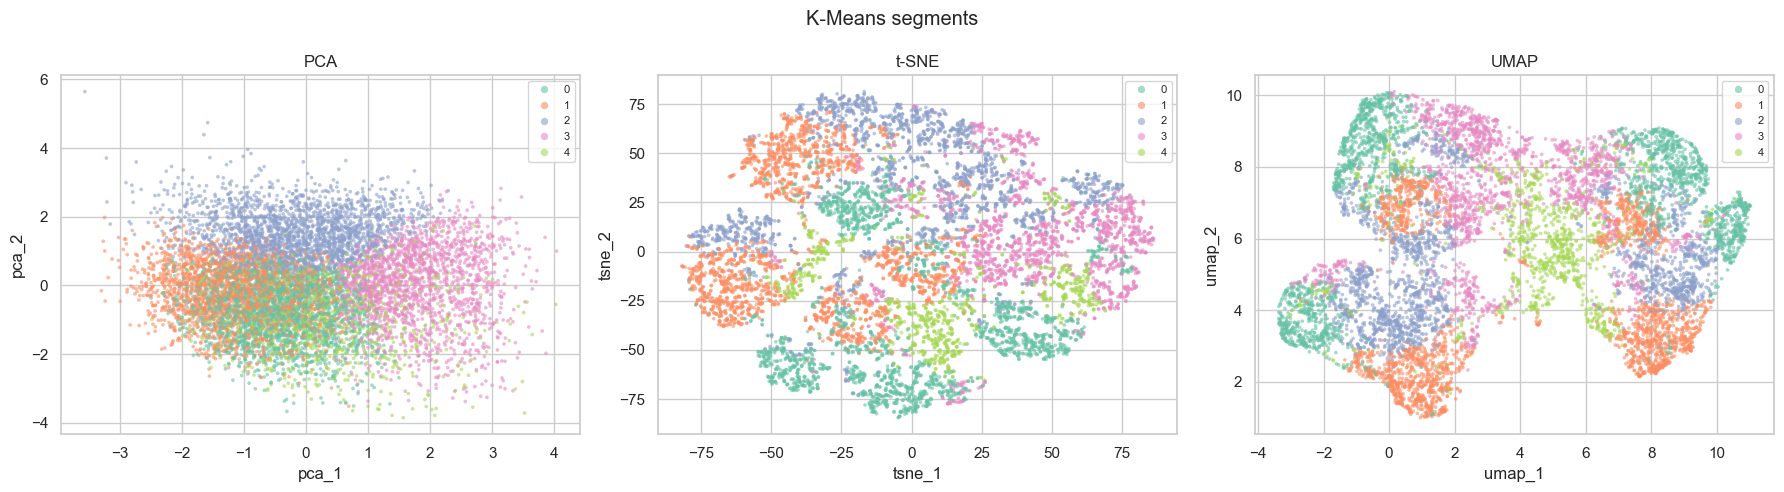

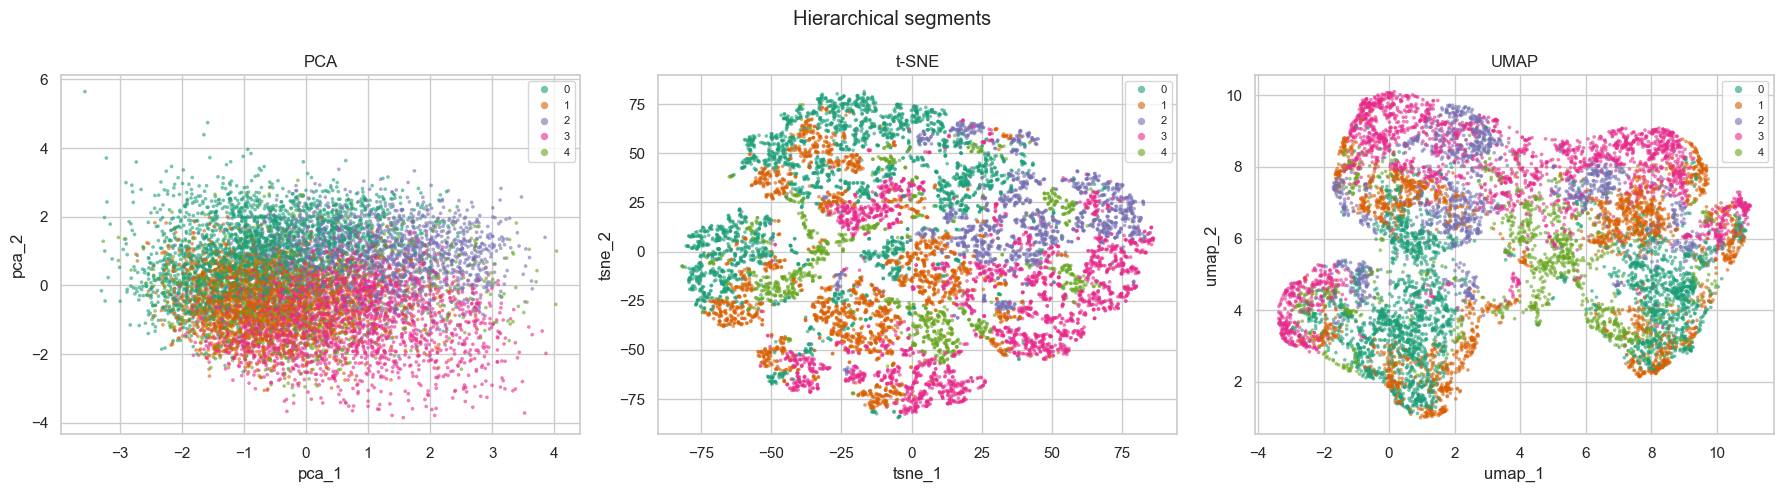

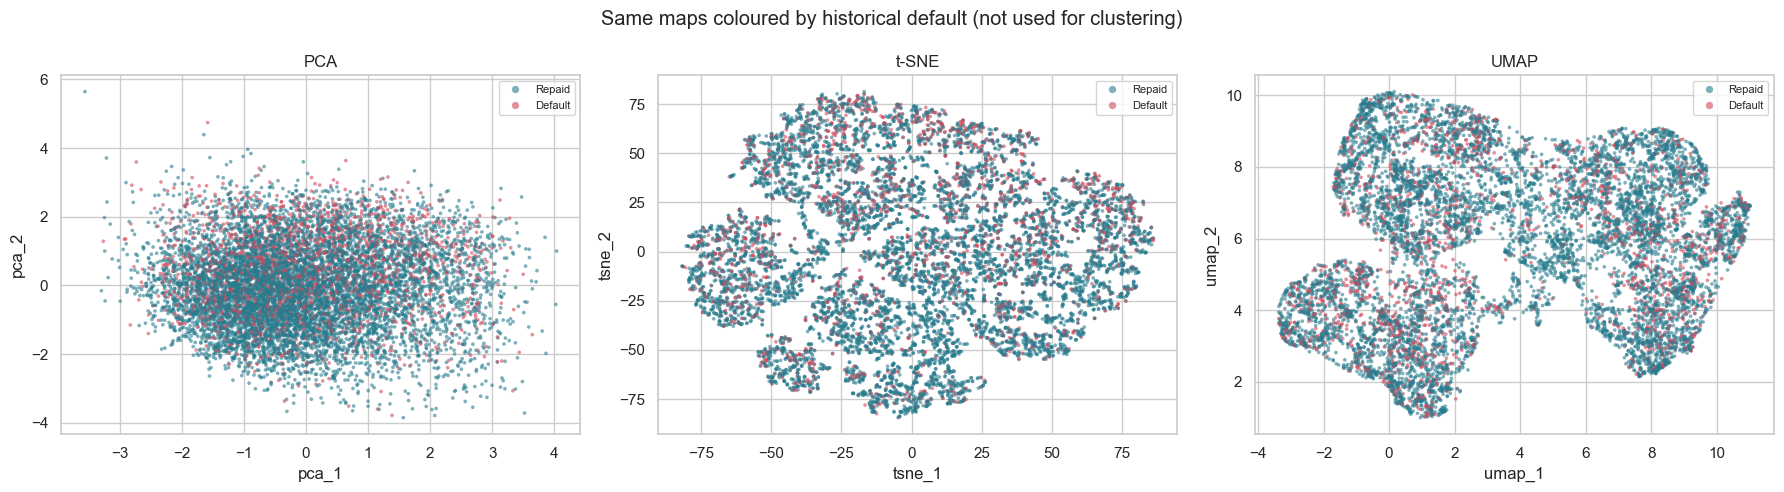

In [89]:
def three_maps(color_col, title, palette):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (x, y, name) in zip(axes, [("pca_1", "pca_2", "PCA"), ("tsne_1", "tsne_2", "t-SNE"), ("umap_1", "umap_2", "UMAP")]):
        sns.scatterplot(data=sample, x=x, y=y, hue=color_col, palette=palette, s=7, alpha=0.6, linewidth=0, ax=ax)
        ax.set_title(name); ax.legend(markerscale=2, fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

three_maps("kmeans_cluster", "K-Means segments", sns.color_palette("Set2", 5))
three_maps("hier_cluster", "Hierarchical segments", sns.color_palette("Dark2", 5))
sample["Outcome"] = sample["Default"].map({0: "Repaid", 1: "Default"})
three_maps("Outcome", "Same maps coloured by historical default (not used for clustering)",
           {"Repaid": "#287C8E", "Default": "#D1495B"})

## 8. Cluster profiling

In [91]:
g = df.groupby("kmeans_cluster")
profile = pd.DataFrame({
    "borrowers": g.size(),
    "share_pct": g.size() / len(df) * 100,
    "median_income": g["revenue"].median(),
    "median_dti": g["dti_n"].median(),
    "median_loan_amnt": g["loan_amnt"].median(),
    "median_fico": g["fico_n"].median(),
    "mean_emp_years": g["emp_years"].mean(),
    "median_loan_to_income": g["loan_to_income"].median(),
    "pct_rent": g["home_ownership_n"].apply(lambda s: (s == "RENT").mean() * 100),
    "pct_mortgage": g["home_ownership_n"].apply(lambda s: (s == "MORTGAGE").mean() * 100),
    "pct_own": g["home_ownership_n"].apply(lambda s: (s == "OWN").mean() * 100),
    "pct_debt_consolidation": g["purpose"].apply(lambda s: (s == "debt_consolidation").mean() * 100),
    "pct_credit_card": g["purpose"].apply(lambda s: (s == "credit_card").mean() * 100),
    "pct_home_improvement": g["purpose"].apply(lambda s: (s == "home_improvement").mean() * 100),
})
profile.round(3).T

kmeans_cluster,0,1,2,3,4
borrowers,321694.000,314600.000,292625.000,278497.000,139216.000
share_pct,23.889,23.362,21.730,20.681,10.338
median_income,72000.000,58000.000,43000.000,100000.000,75000.000
median_dti,16.580,14.870,24.690,17.260,13.490
median_loan_amnt,9600.000,8000.000,14175.000,26400.000,12000.000
median_fico,682.000,682.000,687.000,697.000,762.000
mean_emp_years,9.067,2.404,5.666,6.683,6.040
median_loan_to_income,0.125,0.144,0.325,0.264,0.160
pct_rent,29.993,59.074,51.111,23.235,27.910
pct_mortgage,59.972,31.648,34.750,67.715,59.954


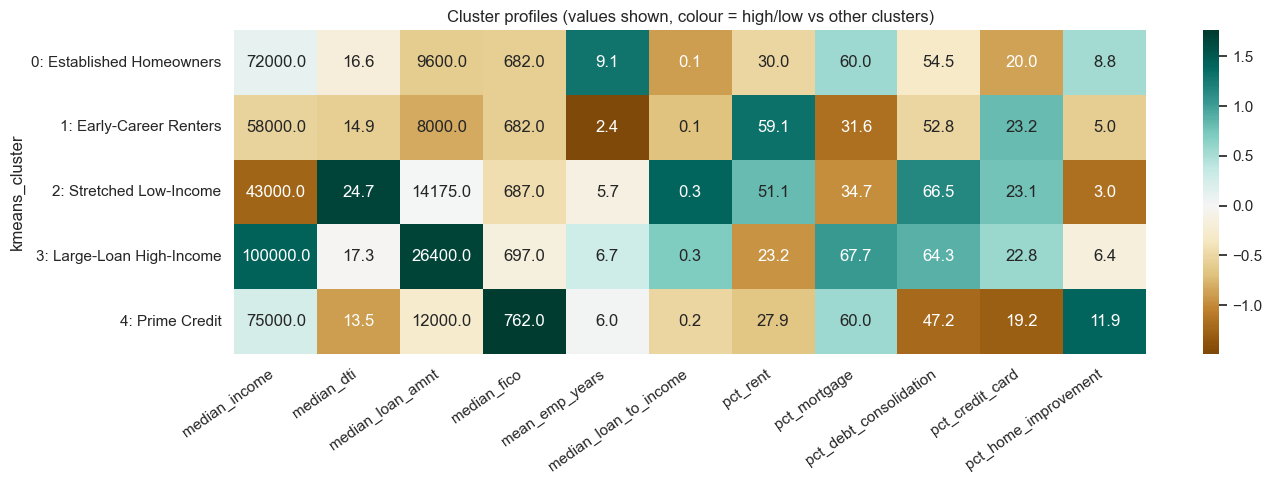

In [92]:
# descriptive names given AFTER looking at the profiles above
CLUSTER_NAMES = {0: "Established Homeowners", 1: "Early-Career Renters", 2: "Stretched Low-Income",
                 3: "Large-Loan High-Income", 4: "Prime Credit"}
cols = ["median_income", "median_dti", "median_loan_amnt", "median_fico", "mean_emp_years",
        "median_loan_to_income", "pct_rent", "pct_mortgage", "pct_debt_consolidation",
        "pct_credit_card", "pct_home_improvement"]
zscores = (profile[cols] - profile[cols].mean()) / profile[cols].std()
plt.figure(figsize=(14, 5))
sns.heatmap(zscores, annot=profile[cols].round(1), fmt="", cmap="BrBG", center=0,
            yticklabels=[f"{i}: {CLUSTER_NAMES[i]}" for i in profile.index])
plt.xticks(rotation=35, ha="right"); plt.title("Cluster profiles (values shown, colour = high/low vs other clusters)")
plt.tight_layout(); plt.show()

## 9. Default pattern analysis


,segment,borrowers,defaults,default_rate_pct,ci_low_pct,ci_high_pct,lift_vs_portfolio
kmeans_cluster,,,,,,,
0,Established Homeowners,321694,53636,16.67,16.54,16.80,0.83
1,Early-Career Renters,314600,57058,18.14,18.00,18.27,0.91
2,Stretched Low-Income,292625,85106,29.08,28.92,29.25,1.46
3,Large-Loan High-Income,278497,61534,22.10,21.94,22.25,1.11
4,Prime Credit,139216,11670,8.38,8.24,8.53,0.42


chi2 = 30,533, dof = 4, p = 0, Cramer's V = 0.15


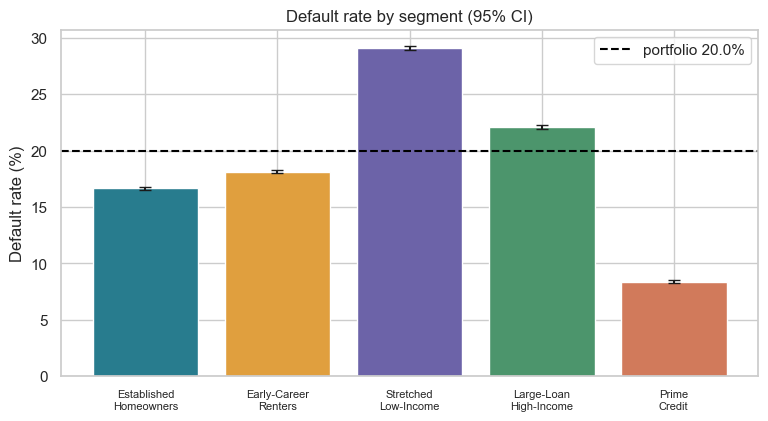

In [94]:
def wilson_ci(defaults, n, z=1.96):
    p = defaults / n
    centre = (p + z**2 / (2*n)) / (1 + z**2 / n)
    half = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

dtab = df.groupby("kmeans_cluster")["Default"].agg(borrowers="size", defaults="sum")
dtab["default_rate_pct"] = dtab["defaults"] / dtab["borrowers"] * 100
lo, hi = wilson_ci(dtab["defaults"], dtab["borrowers"])
dtab["ci_low_pct"], dtab["ci_high_pct"] = lo * 100, hi * 100
dtab["lift_vs_portfolio"] = dtab["default_rate_pct"] / overall
dtab.insert(0, "segment", [CLUSTER_NAMES[i] for i in dtab.index])
display(dtab.round(2))

# chi-square test + effect size
table = pd.crosstab(df["kmeans_cluster"], df["Default"])
chi2, p, dof, _ = chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print(f"chi2 = {chi2:,.0f}, dof = {dof}, p = {p:.3g}, Cramer's V = {cramers_v:.2f}")

err = [dtab["default_rate_pct"] - dtab["ci_low_pct"], dtab["ci_high_pct"] - dtab["default_rate_pct"]]
plt.figure(figsize=(9, 4.5))
plt.bar(range(5), dtab["default_rate_pct"], yerr=err, capsize=4, color=["#287C8E", "#E09F3E", "#6C63A8", "#4C956C", "#D17A5B"])
plt.axhline(overall, color="black", ls="--", label=f"portfolio {overall:.1f}%")
plt.xticks(range(5), [CLUSTER_NAMES[i].replace(" ", "\n", 1) for i in range(5)], fontsize=8)
plt.ylabel("Default rate (%)"); plt.title("Default rate by segment (95% CI)"); plt.legend(); plt.show()

kmeans_cluster,Established Homeowners,Early-Career Renters,Stretched Low-Income,Large-Loan High-Income,Prime Credit
issue_year,,,,,
2007,NaN,24.0,NaN,NaN,NaN
2008,25.7,18.7,28.6,NaN,11.3
2009,16.5,13.5,19.4,20.8,8.8
2010,16.8,14.8,20.1,16.0,7.5
2011,15.3,15.6,22.9,20.4,7.8
2012,14.0,14.6,22.5,19.4,7.7
2013,12.6,13.8,22.2,17.1,6.2
2014,15.0,16.0,26.9,19.5,7.4
2015,16.5,17.4,29.2,21.6,7.6


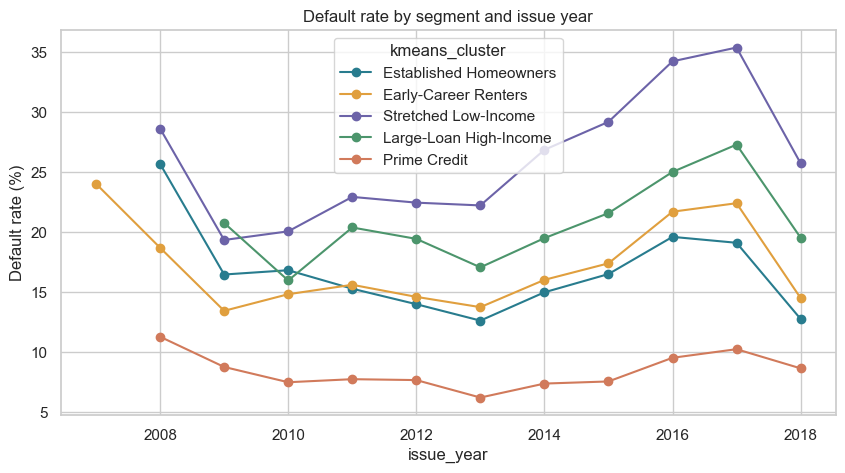

In [95]:
# does the ranking hold in every year? (only years with >= 200 loans per segment)
cnt = df.groupby(["issue_year", "kmeans_cluster"]).size().unstack()
by_year = (df.groupby(["issue_year", "kmeans_cluster"])["Default"].mean().unstack() * 100).where(cnt >= 200)
display(by_year.rename(columns=CLUSTER_NAMES).round(1))
by_year.rename(columns=CLUSTER_NAMES).plot(
    marker="o", figsize=(10, 5),
    color=["#287C8E", "#E09F3E", "#6C63A8", "#4C956C", "#D17A5B"]
)
plt.ylabel("Default rate (%)"); plt.title("Default rate by segment and issue year"); plt.show()

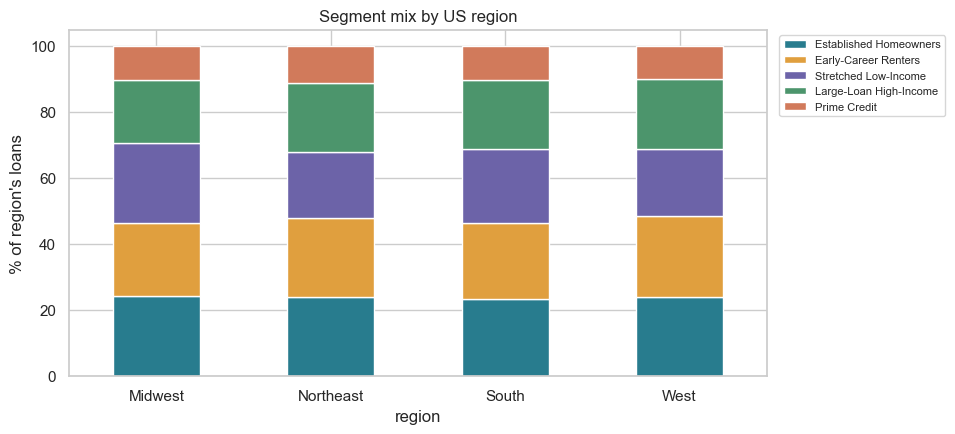

kmeans_cluster,Established Homeowners,Early-Career Renters,Stretched Low-Income,Large-Loan High-Income,Prime Credit
purpose,,,,,
car,13.2,15.7,27.0,25.1,6.5
credit_card,14.2,14.8,25.6,17.5,5.9
debt_consolidation,17.2,18.8,29.7,22.7,8.1
educational,19.6,22.9,20.8,50.0,13.1
home_improvement,15.9,17.7,29.7,23.7,8.1
house,20.0,22.3,34.3,25.4,10.7
major_purchase,15.1,17.6,32.8,30.6,10.1
medical,20.2,22.4,34.9,29.3,12.1
moving,22.2,22.8,40.5,32.9,12.2


In [96]:
# segment mix by region (geographic view) and default by purpose
mix = pd.crosstab(df["region"], df["kmeans_cluster"], normalize="index") * 100
mix.rename(columns=CLUSTER_NAMES).plot.bar(
    stacked=True, figsize=(9, 4.5),
    color=["#287C8E", "#E09F3E", "#6C63A8", "#4C956C", "#D17A5B"]
)
plt.ylabel("% of region's loans"); plt.title("Segment mix by US region"); plt.xticks(rotation=0)
plt.legend(fontsize=8, bbox_to_anchor=(1.01, 1)); plt.show()
(df.groupby(["purpose", "kmeans_cluster"])["Default"].mean().unstack() * 100).rename(columns=CLUSTER_NAMES).round(1)

## 10. Anomaly detection


Anomalies: 219 of 10000 (2.2%)
Default rate - anomalies: 17.8% | others: 20.2%
Share with a feature beyond 3 std - anomalies: 44.3% | others: 1.3%


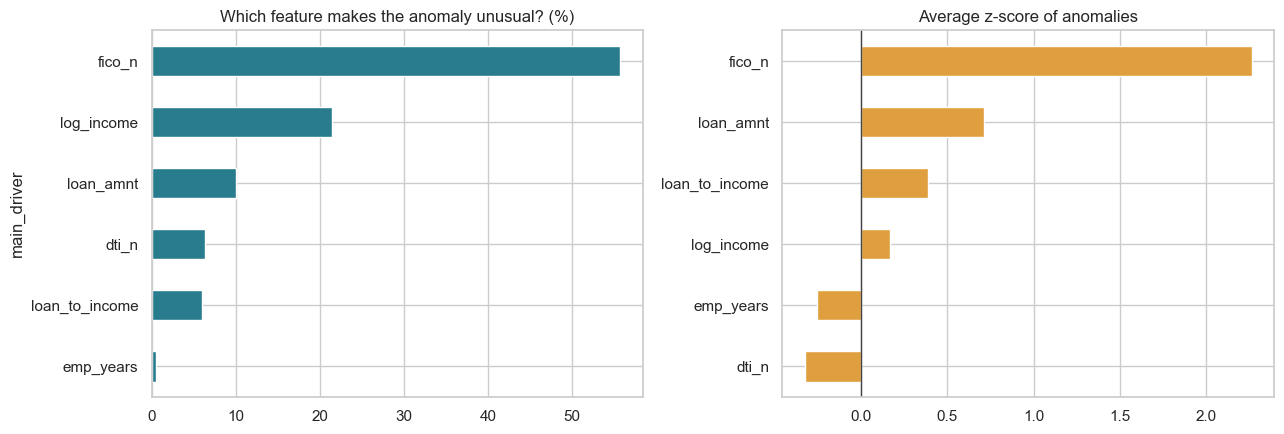

,revenue,dti_n,loan_amnt,fico_n,emp_length,purpose,home_ownership_n,kmeans_cluster,Default,main_driver
1,30000.0,2.12,2500,787.0,8 years,other,RENT,4,0,fico_n
23,109230.0,17.17,35000,787.0,3 years,house,RENT,4,0,fico_n
31,100000.0,9.17,35000,822.0,NI,debt_consolidation,MORTGAGE,4,0,fico_n
127,70000.0,17.74,31300,767.0,3 years,credit_card,RENT,3,0,fico_n
128,104000.0,32.42,40000,782.0,10+ years,debt_consolidation,MORTGAGE,3,0,loan_amnt
156,79000.0,20.43,30000,782.0,2 years,other,MORTGAGE,4,0,fico_n
177,31000.0,9.52,9600,767.0,7 years,debt_consolidation,RENT,4,0,fico_n
398,28000.0,14.44,2300,757.0,10+ years,credit_card,OWN,4,0,fico_n
407,40000.0,32.44,3000,817.0,10+ years,debt_consolidation,OWN,4,0,fico_n
497,8508.0,30.32,2500,737.0,NI,debt_consolidation,RENT,2,1,log_income


In [97]:
scaler = preprocessor.named_transformers_["num"]
z = pd.DataFrame((sample[NUMERIC_FEATURES].values - scaler.mean_) / scaler.scale_, columns=NUMERIC_FEATURES)
sample["is_anomaly"] = (sample["dbscan_cluster"] == -1).astype(int)
sample["main_driver"] = z.abs().idxmax(axis=1)
sample["max_abs_z"] = z.abs().max(axis=1).values
sample["n_extreme_features"] = (z.abs() > 3).sum(axis=1).values   # features beyond 3 std

anom = sample[sample["is_anomaly"] == 1]
normal = sample[sample["is_anomaly"] == 0]
print(f"Anomalies: {len(anom)} of {len(sample)} ({len(anom)/len(sample):.1%})")
print(f"Default rate - anomalies: {anom['Default'].mean():.1%} | others: {normal['Default'].mean():.1%}")
print(f"Share with a feature beyond 3 std - anomalies: {(anom['n_extreme_features']>0).mean():.1%} | others: {(normal['n_extreme_features']>0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
anom["main_driver"].value_counts(normalize=True).mul(100).sort_values().plot.barh(ax=axes[0], color="#287C8E")
axes[0].set_title("Which feature makes the anomaly unusual? (%)")
z.loc[anom.index].mean().sort_values().plot.barh(ax=axes[1], color="#E09F3E")
axes[1].axvline(0, color="#444444", lw=1); axes[1].set_title("Average z-score of anomalies")
plt.tight_layout(); plt.show()

anom[["revenue", "dti_n", "loan_amnt", "fico_n", "emp_length", "purpose", "home_ownership_n",
      "kmeans_cluster", "Default", "main_driver"]].head(10)

Anomalies are mainly **borrowers with unusually high FICO scores or income levels**. Their default rate is *not* higher than that of normal borrowers. These records are unusual but not necessarily risky, so they should be **flagged for analyst review rather than automatically rejected**.

## 11. Save the model with pickle 

In [33]:
import os, pickle
os.makedirs("models", exist_ok=True)

# Everything needed to put a NEW borrower into a segment is stored in one dictionary
model_bundle = {
    "caps": caps,                         # outlier limits
    "emp_length_map": EMP_MAP,            # '5 years' -> 5
    "preprocessor": preprocessor,         # scaler + one-hot encoder
    "pca": pca,                           # PCA (7 components)
    "kmeans": kmeans,                     # the trained K-Means model
    "label_map": old_to_new,              # K-Means id -> id ordered by FICO
    "feature_columns": feature_cols,
    "cluster_names": CLUSTER_NAMES,
}
with open("models/model.pkl", "wb") as f:
    pickle.dump(model_bundle, f)
print("Saved models/model.pkl")

Saved models/model.pkl


In [34]:
# Load the model back from the pickle file and use it on a brand-new borrower
with open("models/model.pkl", "rb") as f:
    loaded = pickle.load(f)

def predict_segment(person, bundle):
    """Return the segment name for one borrower (a dict of raw values)."""
    row = pd.DataFrame([person])
    row["emp_years"] = bundle["emp_length_map"].get(person.get("emp_length"), np.nan)
    row = engineer_features(row, bundle["caps"])
    z_new = bundle["pca"].transform(bundle["preprocessor"].transform(row[bundle["feature_columns"]]))
    seg_id = int(bundle["label_map"][bundle["kmeans"].predict(z_new)[0]])
    return seg_id, bundle["cluster_names"][seg_id]

example = {"revenue": 65000, "dti_n": 17, "loan_amnt": 12000, "fico_n": 780,
           "emp_length": "5 years", "purpose": "credit_card", "home_ownership_n": "MORTGAGE"}
print(predict_segment(example, loaded))

# sanity check: the loaded model reproduces the labels we got during training
test = sample.head(2000)
ok = [predict_segment({"revenue": r.revenue, "dti_n": r.dti_n, "loan_amnt": r.loan_amnt, "fico_n": r.fico_n,
                       "emp_length": r.emp_length, "purpose": r.purpose,
                       "home_ownership_n": r.home_ownership_n}, loaded)[0] == r.kmeans_cluster
      for r in test.itertuples()]
print("Agreement with training labels:", np.mean(ok))

(4, 'Prime Credit')
Agreement with training labels: 1.0


In [35]:
# Export the small files that the Streamlit dashboard reads
os.makedirs("data/processed", exist_ok=True)

sample["cluster_name"] = sample["kmeans_cluster"].map(CLUSTER_NAMES)
keep = ["issue_year", "revenue", "dti_n", "loan_amnt", "fico_n", "emp_years", "emp_length",
        "purpose", "home_ownership_n", "addr_state", "region", "loan_to_income", "Default",
        "kmeans_cluster", "hier_cluster", "dbscan_cluster", "is_anomaly", "max_abs_z",
        "main_driver", "pca_1", "pca_2", "tsne_1", "tsne_2", "umap_1", "umap_2", "cluster_name"]
sample[keep].round(4).to_csv("data/processed/dashboard_sample.csv", index=False)

summary = profile.copy()                              # profile of every segment (all borrowers)
summary["defaults"] = dtab["defaults"]
summary["default_rate_pct"] = dtab["default_rate_pct"]
summary["ci_low_pct"], summary["ci_high_pct"] = dtab["ci_low_pct"], dtab["ci_high_pct"]
summary.insert(0, "segment", [CLUSTER_NAMES[i] for i in summary.index])
summary.round(3).to_csv("data/processed/app_cluster_summary.csv", index=False)

by_year.rename(columns=CLUSTER_NAMES).round(2).to_csv("data/processed/app_default_by_year.csv")
comparison.round(3).to_csv("data/processed/app_algorithm_comparison.csv", index=False)
print("Exported dashboard files to data/processed/")

Exported dashboard files to data/processed/


### Conclusions
* K-Means using **k = 5** identified five clear borrower groups; default rates range from **8.4% (Prime Credit) to 29.1% (Stretched Low-Income)** compared with the 20.0% portfolio average - roughly 3.5 times - although `Default` was excluded from clustering.
* **K-Means** performed better than Hierarchical clustering (silhouette 0.145 versus 0.068); **DBSCAN** detected one dense area and around 2% noise, making it useful for anomaly detection.
* FICO score separates risk well, but **affordability** (DTI and loan-to-income) also matters: Stretched Low-Income borrowers have typical FICO scores but the highest default rate.
* Anomalies show unusually high FICO scores or income, not higher risk.

